<a href="https://colab.research.google.com/github/edoardochiarotti/class_datascience/blob/main/2024/02_Data-Cleaning/02_Data-Cleaning-Practice_Solutions.ipynb" target="_blank" rel="noopener"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# PACKAGES
import numpy as np
import pandas as pd
import os
import re
import plotly.express as px

# Data Cleaning: Practice with Pandas

<img src='https://miro.medium.com/v2/resize:fit:720/format:webp/1*noQ6RX4O_IAGmPOyUbEr9Q.jpeg' width="500">

Source: [Data Profiling — Having that First Date with your Data](https://medium.com/codex/data-profiling-having-that-first-date-with-your-data-2e05de50fca7), 
Kirk Borne

## Content

>  Data Scientists spend 80% of their time on data collecting and data cleaning operations. 
>
> The remaining 20% , they complain about cleaning data! 

Start your complaining journey with this notebook! You will explore two datasets, namely Polity5 and Quality of Government (QOG) Environmental Indicators Dataset, which could be useful for your projects. 

You will use Pandas (derived from "panel data"), the go-to package for data analysis and manipulation. Its primary object, the `DataFrame` is extremely useful in wrangling data. You can read more about Pandas in the [documentation](https://pandas.pydata.org/docs/index.html), and should read the notebook "02_Data-Cleaning-Panda-Introduction" before starting this walkthrough. Since Pandas is one of the most used package, you can also find a ton of material online, answering any questions you might have. As always, there is no need to reinvent the wheel, and you should rely on the years of experience and knowledge of programmers who already faced similar issues you might encounter. 

**As good practice, we imported `pandas` and other packages at the top of this notebook, do not forget to run the top cell to import the necessary packages!**

- [Polity5](#polity5)  
    - [Discover Polity5](#discover-polity5)
    - [Select some variables](#select-polity5)
    - [Dealing with Missing Values](#missing-value-polity5)
    - [Removing duplicates](#removing-polity5)
    - [Exploring Polity2](#exploring-polity5)
- [Quality of Government (QOG) Environmental Indicators Dataset](#qog)  
    - [Discover QOG](#import-qog)
    - [Merge QOG and Polity5](#merge-qog)
    - [Further practise [optional]](#practising-qog)
- [Other dataset to explore](#data)


## Polity5 <a name="polity5"></a>

<img src='https://www.thinkpragati.com/wp-content/uploads/2017/03/democracy-comic.png' width="600">

Source: [Amit Varma](https://www.thinkpragati.com/think/brainstorm/802/democracy-vs-republic/attachment/democracy-comic/)


Polity5 is a widely used democracy scale. The raw data as well as the codebook are available [here](http://www.systemicpeace.org/inscrdata.html). 

For this walkthough, we have modified a bit the original version, for example adding iso3 code for countries. You can find the modified version [here](https://raw.githubusercontent.com/edoardochiarotti/class_datascience/main/2023/02_Data-Cleaning/data/polity2_iso3.csv).

### Discover Polity5 <a name="discover-polity5"></a>

- Import the csv 'polity2_iso3.csv' (file provided in the link [here](https://raw.githubusercontent.com/edoardochiarotti/class_datascience/main/2023/02_Data-Cleaning/data/polity2_iso3.csv)) as a panda dataframe (ignore the warning message)

In [2]:
# Your code here...
url_polity = 'https://raw.githubusercontent.com/thurmboris/Data-Science_4_Sustainability/main/data/polity2_iso3.csv'
df_pol = pd.read_csv(url_polity)

/var/folders/50/z62d1r092mvbd7y3wgvjp3jc0000gp/T/ipykernel_67747/1335780363.py:3: DtypeWarning: Columns (0: durable, 1: prior, 2: emonth, 3: eday, 4: eyear, 5: eprec, 6: interim, 7: bmonth, 8: bday, 9: byear, 10: bprec, 11: post, 12: change, 13: d5, 14: sf, 15: regtrans) have mixed types. Specify dtype option on import or set low_memory=False.
  df_pol = pd.read_csv(url_polity)


- Display the first 10 rows to start exploring our dataset

In [3]:
# Your code here...

df_pol.head(10)

,iso3,year,p5,cyear,ccode,scode,country,flag,fragment,democ,...,interim,bmonth,bday,byear,bprec,post,change,d5,sf,regtrans
0,NaN,1800,0,2711800,271,WRT,Wuerttemburg,0,NaN,0,...,NaN,1.0,1.0,1800.0,1.0,-7.0,88.0,1.0,NaN,NaN
1,NaN,1800,0,7301800,730,KOR,Korea,0,NaN,5,...,NaN,1.0,1.0,1800.0,1.0,1.0,88.0,1.0,NaN,NaN
2,NaN,1800,0,2451800,245,BAV,Bavaria,0,NaN,0,...,NaN,1.0,1.0,1800.0,1.0,-10.0,88.0,1.0,NaN,NaN
3,NaN,1801,0,7301801,730,KOR,Korea,0,NaN,5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,1801,0,2711801,271,WRT,Wuerttemburg,0,NaN,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,1801,0,2451801,245,BAV,Bavaria,0,NaN,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,1802,0,7301802,730,KOR,Korea,0,NaN,5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,1802,0,2711802,271,WRT,Wuerttemburg,0,NaN,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,1802,0,2451802,245,BAV,Bavaria,0,NaN,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,1803,0,7301803,730,KOR,Korea,0,NaN,5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


- Display the data types of all the variables included in the data.

In [4]:
# Your code here...

df_pol.dtypes

iso3            str
year          int64
p5            int64
cyear         int64
ccode         int64
scode           str
country         str
flag          int64
fragment    float64
democ         int64
autoc         int64
polity        int64
polity2     float64
durable      object
xrreg         int64
xrcomp        int64
xropen        int64
xconst        int64
parreg        int64
parcomp       int64
exrec       float64
exconst       int64
polcomp     float64
prior        object
emonth       object
eday         object
eyear        object
eprec        object
interim      object
bmonth       object
bday         object
byear        object
bprec        object
post         object
change       object
d5           object
sf           object
regtrans     object
dtype: object

Notice that Pandas is using different names for data types. Here is a description:

|Pandas type|Native Python type|Description|
|:-------|:-------|:----------|
|`object` | `string` | The most general dtype. Will be assigned to your column if column has mixed types (numbers and strings). |
|`int64` | `int` | Numeric characters. 64 refers to the memory allocated to hold this character. |
|`float64` | `float` | Numeric characters with decimals. If a column contains numbers and NaNs (see below), pandas will default to float64, in case your missing value has a decimal.|

When you need to convert one column to another type, one option is to rely on `astype`([Documentation](http://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.astype.html)).

### Select some variables <a name="select-polity5"></a>

In the following, we will work with one of the variable included in the dataset, namely "polity2". 

- In the [user manual of Polity5](https://www.systemicpeace.org/inscrdata.html), go and read section 2 *Indicators of Democracy and Autocracy (Composite Indices)* to better understand our variable. What do the values in "polity2" represent?

- Using `loc` ([Documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.loc.html)), create a subset dataframe that contains the variables 'iso3', 'country', 'year', 'polity2' and display it. How many observations (i.e., rows) do we have?

In [5]:
# Your code here...

df_pol2 = df_pol.loc[:,['iso3', 'country', 'year', 'polity2']]
df_pol2

,iso3,country,year,polity2
0,NaN,Wuerttemburg,1800,-7.0
1,NaN,Korea,1800,1.0
2,NaN,Bavaria,1800,-10.0
3,NaN,Korea,1801,1.0
4,NaN,Wuerttemburg,1801,-7.0
...,...,...,...,...
17569,ZWE,Zimbabwe,2014,4.0
17570,ZWE,Zimbabwe,2015,4.0
17571,ZWE,Zimbabwe,2016,4.0
17572,ZWE,Zimbabwe,2017,4.0


### Dealing with Missing Values <a name="missing-value-polity5"></a>

Ok, now that we have selected our first ingredients, we need to start cleaning our dataset.

One of the first step is to identify and deal with missing values, `NaN`. `NaN` stands for **Not a Number**, and it can be interpreted as a value that is undefined or unrepresentable. When you import csv data, the following values will be interpreted as `NaN`: ‘’, ‘#N/A’, ‘#N/A N/A’, ‘#NA’, ‘-1.#IND’, ‘-1.#QNAN’, ‘-NaN’, ‘-nan’, ‘1.#IND’, ‘1.#QNAN’, ‘<NA>’, ‘N/A’, ‘NA’, ‘NULL’, ‘NaN’, ‘n/a’, ‘nan’, ‘null’. 
    
The `isna()` method ([Documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isna.html)) allows to detect `NaN`. It returns a dataframe of the same size that indicates if a value is a `NaN` with `True`, or not with `False`:

In [6]:
df_pol2.isna()

,iso3,country,year,polity2
0,True,False,False,False
1,True,False,False,False
2,True,False,False,False
3,True,False,False,False
4,True,False,False,False
...,...,...,...,...
17569,False,False,False,False
17570,False,False,False,False
17571,False,False,False,False
17572,False,False,False,False


- How many missing values do we have for each variable?

*Hints*: Remember that `True` is associated with the value `1` and `False` with the value `0`, so you can sum over a column of `True`/`False` to  count the number of `True` statement. You can sum over a dataframe column using the method `.sum()` ([Documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sum.html)).

In [7]:
# Your code here...

df_pol2.isna().sum() 

iso3       1270
country       0
year          0
polity2     263
dtype: int64

What should we do with the missing missing values? There are several potential strategies:
1. Delete the observations (rows) with missing values;
2. Impute missing values based on our knowledge;
3. Predict the missing values using, for instance, an algorithm. 

The strategy we decide to implement depends on the context! And **you should always justify and carefully document your assumptions.** 

Ok let's try to gain further information on our missing values, starting with the variable "iso3".

- Create a subset dataframe containing only the observations with missing "iso3" values. Note: you should use the `loc` method.
- With the method `.sort_values()` ([Documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sort_values.html)), sort your dataframe by "year" and "country".
- Display your full dataframe. One option is to to print your dataframe as string, using the method `.to_string()` ([Documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_string.html))

In [8]:
# Your code here...

df_pol2_nan = df_pol2.loc[df_pol2['iso3'].isna(),:]
df_pol2_nan = df_pol2_nan.sort_values(by=['year','country'])
print(df_pol2_nan.to_string())

     iso3                country  year  polity2
2     NaN                Bavaria  1800    -10.0
1     NaN                  Korea  1800      1.0
0     NaN           Wuerttemburg  1800     -7.0
5     NaN                Bavaria  1801    -10.0
3     NaN                  Korea  1801      1.0
4     NaN           Wuerttemburg  1801     -7.0
8     NaN                Bavaria  1802    -10.0
6     NaN                  Korea  1802      1.0
7     NaN           Wuerttemburg  1802     -7.0
10    NaN                Bavaria  1803    -10.0
9     NaN                  Korea  1803      1.0
11    NaN           Wuerttemburg  1803     -7.0
12    NaN                Bavaria  1804    -10.0
13    NaN                  Korea  1804      1.0
14    NaN           Wuerttemburg  1804     -7.0
17    NaN                Bavaria  1805    -10.0
16    NaN                  Korea  1805      1.0
15    NaN           Wuerttemburg  1805     -7.0
18    NaN                Bavaria  1806    -10.0
20    NaN                  Korea  1806  

- What do you notice when looking at the list of countries? To make it easier, print the countries with missing "iso3". You can use the method `unique()` ([Documentation](https://pandas.pydata.org/docs/reference/api/pandas.unique.html)) to extract the unique values in a dataframe.

In [9]:
# Your code here...

country_missingiso = df_pol2_nan['country'].unique()
print(country_missingiso)

<StringArray>
[              'Bavaria',                 'Korea',          'Wuerttemburg',
                'Saxony',                'Modena',                 'Parma',
              'Sardinia',               'Tuscany',          'Two Sicilies',
                 'Baden',         'Gran Colombia',    'United Province CA',
                'Serbia',     'Orange Free State',        'Czechoslovakia',
           'Yemen North',                  'USSR',          'Germany East',
          'Germany West',              'Pakistan',         'South Vietnam',
           'Yemen South',               'Vietnam',            'Yugoslavia',
              'Ethiopia', 'Serbia and Montenegro',            'Montenegro',
           'Sudan-North']
Length: 28, dtype: str


It seems that some of these "countries" are states that ceased to exist, either because they split (e.g., Czechoslovakia, Yugoslavia) or merged (e.g., Bavaria, Saxony). However, some still exist today (e.g., Ethiopia). We are going to explore what is happening with these countries.

The function `country_search` defines below will be useful. It takes as input a dataframe and a country name, and prints, independently of the casing, a dataframe with all the observations containing this country name: 

In [10]:
def country_search(df, country):
    df_out = df.loc[[bool(re.search(country, i, flags = re.IGNORECASE)) for i in df['country']],:]
    df_out = df_out.sort_values(by=['year'])
    print(df_out.to_string())

- Using the function `country_search` (do not forget to run the cell above), display the rows for which the column "country" contains the word "Serbia". By looking at the result, can you tell what happened to Serbia in 2006?

In [11]:
# Your code here...

country_search(df_pol2_nan, 'serbia')

     iso3                country  year  polity2
224   NaN                 Serbia  1830     -7.0
230   NaN                 Serbia  1831     -7.0
252   NaN                 Serbia  1832     -7.0
261   NaN                 Serbia  1833     -7.0
272   NaN                 Serbia  1834     -7.0
286   NaN                 Serbia  1835     -7.0
295   NaN                 Serbia  1836     -7.0
301   NaN                 Serbia  1837     -7.0
318   NaN                 Serbia  1838      2.0
333   NaN                 Serbia  1839      2.0
344   NaN                 Serbia  1840      2.0
357   NaN                 Serbia  1841      2.0
363   NaN                 Serbia  1842      2.0
369   NaN                 Serbia  1843      2.0
387   NaN                 Serbia  1844      2.0
394   NaN                 Serbia  1845      2.0
410   NaN                 Serbia  1846      2.0
420   NaN                 Serbia  1847      2.0
429   NaN                 Serbia  1848      2.0
439   NaN                 Serbia  1849  

- Do the same for "vietnam"

In [12]:
# Your code here...

country_search(df_pol2_nan, 'vietnam')

     iso3        country  year  polity2
912   NaN  South Vietnam  1955     -3.0
917   NaN  South Vietnam  1956     -3.0
921   NaN  South Vietnam  1957     -3.0
928   NaN  South Vietnam  1958     -3.0
936   NaN  South Vietnam  1959     -3.0
945   NaN  South Vietnam  1960     -3.0
949   NaN  South Vietnam  1961     -3.0
955   NaN  South Vietnam  1962     -3.0
964   NaN  South Vietnam  1963     -3.0
974   NaN  South Vietnam  1964     -3.0
976   NaN  South Vietnam  1965      NaN
986   NaN  South Vietnam  1966      NaN
992   NaN  South Vietnam  1967      NaN
1000  NaN  South Vietnam  1968      NaN
1011  NaN  South Vietnam  1969      NaN
1021  NaN  South Vietnam  1970      NaN
1023  NaN  South Vietnam  1971      NaN
1031  NaN  South Vietnam  1972      NaN
1039  NaN  South Vietnam  1973      0.0
1046  NaN  South Vietnam  1974      0.0
1053  NaN  South Vietnam  1975      0.0
1058  NaN        Vietnam  1976     -7.0
1071  NaN        Vietnam  1977     -7.0
1075  NaN        Vietnam  1978     -7.0


The countries with missing iso3 values from 2011 onwards still exist today and might be needed for our analysis. Hence, instead of just deleting the observations, we are going to replace the nan iso3 with proper values.

- Create a list containing the (unique) countries with missing values from 2011 onwards 

In [13]:
# Your code here...

country_missingiso_from2011 = list(df_pol2_nan.loc[df_pol2_nan['year']>2011,'country'].unique())
country_missingiso_from2011

['Ethiopia', 'Montenegro', 'Serbia', 'Sudan-North', 'Vietnam']

The iso3 code of these countries are: Ethiopia: "ETH", Montenegro: "MNE", Serbia: "SRB", Sudan-North: "SDN" and Vietnam: "VNM"

- For your "polity2" dataframe (dataframe obtained at the end of the previous section, containing all the observations), replace `NaN` values in iso3 with correct iso3 for these 5 countries from 2011 onwards. Check that the substitution worked.

*Hint*: You could use a for loop, and, for instance, the function `zip` ([Documentation](https://docs.python.org/3/library/functions.html#zip))

In [14]:
# Your code here...
newiso3 = ['ETH','MNE','SRB','SDN','VNM']

for c, iso  in zip(country_missingiso_from2011, newiso3):
    df_pol2.loc[(df_pol2['year'] >= 2011) & (df_pol2['country'] == c), 'iso3'] = iso

In [15]:
df_pol2.loc[(df_pol2['country'].isin(country_missingiso_from2011)) & (df_pol2['year'] >= 2011),:]

,iso3,country,year,polity2
1230,MNE,Montenegro,2011,9.0
1231,SRB,Serbia,2011,8.0
1233,ETH,Ethiopia,2011,-3.0
1234,SDN,Sudan-North,2011,-4.0
1235,VNM,Vietnam,2011,-7.0
1236,MNE,Montenegro,2012,9.0
1238,SRB,Serbia,2012,8.0
1239,ETH,Ethiopia,2012,-3.0
1240,VNM,Vietnam,2012,-7.0
1241,SDN,Sudan-North,2012,-4.0


- Drop the remaining rows which have `NaN` in "iso3" and display your new dataframe. How many obervations do we have?

In [16]:
# Your code here...

df_pol2 = df_pol2.loc[df_pol2['iso3'].notna(),:]
df_pol2

,iso3,country,year,polity2
1230,MNE,Montenegro,2011,9.0
1231,SRB,Serbia,2011,8.0
1232,SSD,South Sudan,2011,0.0
1233,ETH,Ethiopia,2011,-3.0
1234,SDN,Sudan-North,2011,-4.0
...,...,...,...,...
17569,ZWE,Zimbabwe,2014,4.0
17570,ZWE,Zimbabwe,2015,4.0
17571,ZWE,Zimbabwe,2016,4.0
17572,ZWE,Zimbabwe,2017,4.0


### Removing duplicates <a name="removing-polity5"></a>

Another common operation of data cleaning consists in removing duplicate obervarions. We should, for instance, only have one polity2 value for a given iso3 (country) and year. Let's check if we have duplicates rows. 

One option is to use the method `.duplicated()` ([Documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.duplicated.html)), which returns `True` if the row has a duplicate and `False` otherwise.

- Create a new dataframe extracting the duplicated rows from from the dataframe previously obtained. To do so, you can create an intermediate Series of Boolean with `.duplicated()`, and you should use as options `subset=['iso3', 'year']` to identify rows with the same iso3-year values, and `keep=False` to keep all duplicates
- Display your new dataframe

In [17]:
# Your code here...

duplicated_rows = df_pol2.duplicated(subset=['iso3', 'year'], keep=False)
df_pol2_duplicates = df_pol2.loc[duplicated_rows,:]
df_pol2_duplicates = df_pol2_duplicates.sort_values(by=['year','country'])
print(df_pol2_duplicates.to_string())

      iso3      country  year  polity2
11323  MNE       Kosovo  2011      8.0
1230   MNE   Montenegro  2011      9.0
14686  SDN        Sudan  2011     -2.0
1234   SDN  Sudan-North  2011     -4.0
11324  MNE       Kosovo  2012      8.0
1236   MNE   Montenegro  2012      9.0
11325  MNE       Kosovo  2013      8.0
1243   MNE   Montenegro  2013      9.0
11326  MNE       Kosovo  2014      8.0
1251   MNE   Montenegro  2014      9.0
11327  MNE       Kosovo  2015      8.0
1259   MNE   Montenegro  2015      9.0
11328  MNE       Kosovo  2016      8.0
1260   MNE   Montenegro  2016      9.0
11329  MNE       Kosovo  2017      8.0
1271   MNE   Montenegro  2017      9.0
11330  MNE       Kosovo  2018      8.0
1272   MNE   Montenegro  2018      9.0


What should we do with these duplicates? It is worth looking at some obervations before and after the duplicates to get a better understanding.

- Extract the rows with iso3 equal to "MNE" and "SDN" after 2000 from the "polity2" dataframe (dataframe obtained at the end of previous section, after removing rows with NaN values)

In [18]:
# Your code here...

df_pol2_duplicates_extended = df_pol2.loc[(df_pol2['iso3'].isin(df_pol2_duplicates['iso3'])) & (df_pol2['year']>2000),:].sort_values(['iso3','year'])
print(df_pol2_duplicates_extended.to_string())

      iso3      country  year  polity2
11320  MNE       Kosovo  2008      8.0
11321  MNE       Kosovo  2009      8.0
11322  MNE       Kosovo  2010      8.0
1230   MNE   Montenegro  2011      9.0
11323  MNE       Kosovo  2011      8.0
1236   MNE   Montenegro  2012      9.0
11324  MNE       Kosovo  2012      8.0
1243   MNE   Montenegro  2013      9.0
11325  MNE       Kosovo  2013      8.0
1251   MNE   Montenegro  2014      9.0
11326  MNE       Kosovo  2014      8.0
1259   MNE   Montenegro  2015      9.0
11327  MNE       Kosovo  2015      8.0
1260   MNE   Montenegro  2016      9.0
11328  MNE       Kosovo  2016      8.0
1271   MNE   Montenegro  2017      9.0
11329  MNE       Kosovo  2017      8.0
1272   MNE   Montenegro  2018      9.0
11330  MNE       Kosovo  2018      8.0
14676  SDN        Sudan  2001     -6.0
14677  SDN        Sudan  2002     -6.0
14678  SDN        Sudan  2003     -6.0
14679  SDN        Sudan  2004     -6.0
14680  SDN        Sudan  2005     -3.0
14681  SDN        Sudan  

South Sudan gained independence from Sudan in 2011. Hence, in our dataset, Sudan is called Sudan-North starting from 2011. We will drop the observation "Sudan-2011", and rename "Sudan-North" as "Sudan". Moreover, Kosovo does not have an official iso3 code and the state is only partially recognized. We could still make use of these observations, so we'll replace the Kosovo code with the unofficial "XXK".

In our "polity2" dataframe (dataframe obtained at the end of previous section, after removing rows with NaN values):
- Drop the observation with country "Sudan" and year 2011
- Remame "Sudan-North" as "Sudan"
- Replace the Kosovo iso3 code with "XXK"
- Check that we do not have any duplicated rows left

In [19]:
# Your code here...

df_pol2 = df_pol2.loc[~((df_pol2['country'] == 'Sudan') & (df_pol2['year'] == 2011)),:]
df_pol2.loc[df_pol2['country'] == 'Sudan-North','country'] = 'Sudan'
df_pol2.loc[df_pol2['country'] == 'Kosovo','iso3'] = 'XXK'
df_pol2.duplicated(subset=['iso3', 'year'], keep=False).sum()

np.int64(0)

### Exploring Polity2 <a name="exploring-polity5"></a>

We'll now explore a bit the Polity2 variable.

- Display the first and last year included in the dataset

In [20]:
# Your code here...
years_pol2 = list(df_pol2['year'].unique())
print(f'The first year is: {min(years_pol2)}')
print(f'The last year is: {max(years_pol2)}')

The first year is: 1776
The last year is: 2020


As mentioned in the documentation, Polity is a scale from -10 (complete autocracy) to 10 ("perfect" democracy). The index is computed as DEMOC-AUTOC, with DEMOC being a democracy score and AUTOC a autocracy score. More precisely each (DEMOC/AUTOC) is computed as sum of grades evaluating: "Competitiveness of Executive Recruitment", "Openness of Executive Recruitment", "Constraints on Chief Executive", "Regulation of participation", "Competitiveness of Participation".

- Print a sorted list of the (unique) "polity2" values

In [21]:
# Your code here...
print(sorted(list(df_pol2['polity2'].unique())))

[np.float64(-88.0), np.float64(-66.0), np.float64(-10.0), np.float64(-9.0), np.float64(-8.0), np.float64(-7.0), np.float64(-6.0), np.float64(-5.0), np.float64(-4.0), np.float64(-3.0), np.float64(-2.0), np.float64(-1.0), np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(nan), np.float64(10.0)]


As you can see, there are values that are not between -10 and 10. As per the user manual: -66 and -88 corresponds respectively to "interuption" and "transition". What do you think we should do with these values?
1. One option would be to replace these values with NaN, since they are missing. 
2. Another would be to check if we could replace these values with others, more meaningful ones. For example, we could check the countries/years where these values appear, and if the indicator is stable the years before and after the interuption, then replace -66/-88 with the value taken from the years before/after. In such case, we would need to carefully justify our assumptions!

In this walkthrough, we'll go with option 1.

- Replace with values -66 and -88 with NaN. Hint, you can use `np.nan`. Check that your replacement worked. 

In [22]:
# Your code here...
df_pol2.loc[df_pol2['polity2'] < -10, 'polity2'] = np.nan
print(sorted(list(df_pol2['polity2'].unique())))

[np.float64(-10.0), np.float64(-9.0), np.float64(-8.0), np.float64(-7.0), np.float64(-6.0), np.float64(-5.0), np.float64(-4.0), np.float64(-3.0), np.float64(-2.0), np.float64(-1.0), np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(nan), np.float64(10.0)]


Finally, as a teaser for next week, let's do a map of the number of observations per countries. You can simply run the code below. It groups the observation by iso3 code, and then create a map using the [plotly express module](https://plotly.com/python/plotly-express/).

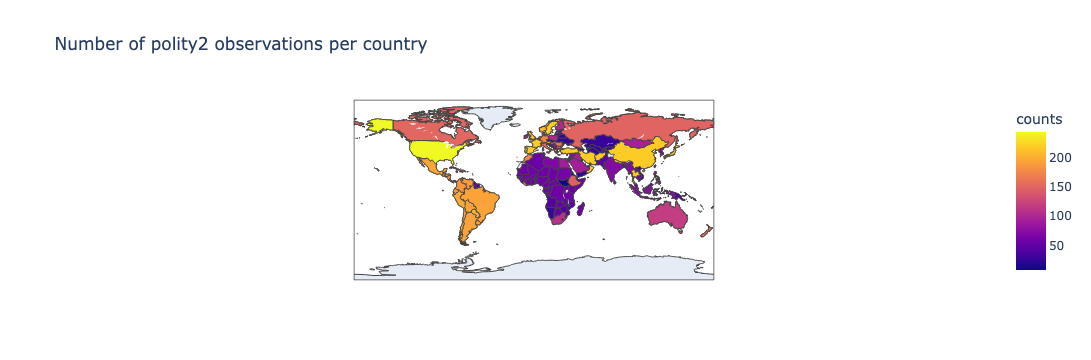

In [23]:
df_map = df_pol2.groupby(['iso3']).size().reset_index(name='counts')
fig = px.choropleth(df_map, locations='iso3',
                    locationmode='ISO-3',
                    color='counts', 
                    hover_name='iso3',
                    title = 'Number of polity2 observations per country',
                    color_continuous_scale=px.colors.sequential.Plasma)
fig.show()

## Quality of Government Environmental Indicators <a name="qog"></a>

<img src='https://www.economist.com/cdn-cgi/image/width=834,quality=80,format=auto/sites/default/files/images/2021/08/articles/main/20210814_wwd000.jpg' width="500">

Source: [Cartoon by Kevin KAL Kallaugher](https://www.kaltoons.com/about/), [The Economist](https://www.economist.com/the-world-this-week/2021/08/14/kals-cartoon)

The Quality of Government Environmental Indicators Dataset is a compilation of indicators measuring countries' environmental performance over time, including the presence and stringency of environmental policies, environmental outcomes (emissions, deforestation, etc.), and public opinion on the environment. Codebook and data are available [here](https://www.gu.se/en/quality-government/qog-data/data-downloads/environmental-indicators-dataset).

*Reference: Povitkina, Marina, Natalia Alvarado Pachon & Cem Mert Dalli. 2021. The Quality of Government Environmental Indicators Dataset, version Sep21. University of Gothenburg: The Quality of Government Institute, https://www.gu.se/en/quality-government*

### Discover QoG <a name="import-qog"></a>

- Import data from the Quality of Government Environmental Indicators Dataset and display the first 5 observations and shape. How many observations do we have? How many variables? 

*Hint*: When you go on the webpage of the Environmental Indicators Dataset, you can directly import from a URL by copying the link address of the dataset! 

In [24]:
# Your code here...

url_qog = 'https://www.qogdata.pol.gu.se/data/qog_ei_sept21.xlsx'
df_qog = pd.read_excel(url_qog)

# Alternatively, with CSV:
# pd.read_csv('https://www.qogdata.pol.gu.se/data/qog_ei_ts_sept21.csv')

In [25]:
df_qog.head(5)

,cname_wb,ccode_wb,year,cname_qog,ccode_qog,ccodealp,ccodealp_year,ccodecow,ccodevdem,cname_year,...,wdi_precip,wdi_tpa,wvs_ameop,wvs_ceom,wvs_deop,wvs_epmip,wvs_epmpp,wvs_imeop,wvs_pedp,wvs_ploem
0,Afghanistan,4.0,1946,Afghanistan,4,AFG,AFG46,700.0,36.0,Afghanistan 1946,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Afghanistan,4.0,1947,Afghanistan,4,AFG,AFG47,700.0,36.0,Afghanistan 1947,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,4.0,1948,Afghanistan,4,AFG,AFG48,700.0,36.0,Afghanistan 1948,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,4.0,1949,Afghanistan,4,AFG,AFG49,700.0,36.0,Afghanistan 1949,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,4.0,1950,Afghanistan,4,AFG,AFG50,700.0,36.0,Afghanistan 1950,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df_qog_shape = df_qog.shape
print(f'There are {df_qog_shape[0]} observations and {df_qog_shape[1]} variables!')

Check QoG codebook to discover all the available variables!

### Merge QoG and Polity5 <a name="merge-qog"></a>

We will try to merge the QoG and Polity5 dataset. To do so, we need to properly identify each observation, and the easiest in our case is to rely on the countries iso3 codes and year of observation. However, in QoG, there is not column "iso3". No worries, there is a column with "iso3" code, it is just called "ccodealp":

- Rename the variable "ccodealp" to "iso3"

In [26]:
# Your code here...
df_qog = df_qog.rename(columns={'ccodealp': 'iso3'})

For the merging to be successful, we need the columns to have the same name and data type.

- Check that the variable "year" is of integer type, and "iso3" of string (object) type, if not convert them to the proper type.

In [28]:
# Your code here...
print(f"The format of the year column is: {df_qog['year'].dtype}")
# df_qog["year"] = df_qog["year"].astype(str)
print(f"The format of the iso3 column is: {df_qog['iso3'].dtype}")

The format of the year column is: int64
The format of the iso3 column is: str


Ok, let's try to merge the QoG and Polity5 dataframe

- Merge the QoG and final polity2 dataframes using the `.merge()` method ([Documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.merge.html)). As options, you should use: 
    - `on=["iso3", "year"]` to merge on the iso3 and year columns; 
    - `how="left"` to merge of QoG keys;
    - `validate="one_to_one"` to check if merge keys are unique in both left and right datasets.
- Display your dataframe. How many observations do we have?

In [29]:
# Your code here...

df_qog_pol = pd.merge(df_qog, df_pol2, how='left', on=['iso3', 'year'], validate='one_to_one')
df_qog_pol

,cname_wb,ccode_wb,year,cname_qog,ccode_qog,iso3,ccodealp_year,ccodecow,ccodevdem,cname_year,...,wvs_ameop,wvs_ceom,wvs_deop,wvs_epmip,wvs_epmpp,wvs_imeop,wvs_pedp,wvs_ploem,country,polity2
0,Afghanistan,4.0,1946,Afghanistan,4,AFG,AFG46,700.0,36.0,Afghanistan 1946,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Afghanistan,-10.0
1,Afghanistan,4.0,1947,Afghanistan,4,AFG,AFG47,700.0,36.0,Afghanistan 1947,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Afghanistan,-10.0
2,Afghanistan,4.0,1948,Afghanistan,4,AFG,AFG48,700.0,36.0,Afghanistan 1948,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Afghanistan,-10.0
3,Afghanistan,4.0,1949,Afghanistan,4,AFG,AFG49,700.0,36.0,Afghanistan 1949,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Afghanistan,-10.0
4,Afghanistan,4.0,1950,Afghanistan,4,AFG,AFG50,700.0,36.0,Afghanistan 1950,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Afghanistan,-10.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11717,South Vietnam,NaN,1972,"Vietnam, South",999,VDR,VDR72,NaN,NaN,"Vietnam, South 1972",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11718,South Vietnam,NaN,1973,"Vietnam, South",999,VDR,VDR73,NaN,NaN,"Vietnam, South 1973",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11719,South Vietnam,NaN,1974,"Vietnam, South",999,VDR,VDR74,NaN,NaN,"Vietnam, South 1974",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11720,South Vietnam,NaN,1975,"Vietnam, South",999,VDR,VDR75,NaN,NaN,"Vietnam, South 1975",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Our merge was successful. For instance, we have the same number of rows in the merged dataframe and in the QoG ones. However, most of the time, merging is a complex process and you will encounter some issues. For example, if we did not have removed duplicates in Polity5, then it would have failed! (You can check that by re-running all cells in this notebook except the section on removing duplicates) 

We made great progress but our cleaning is not over: for instance, for some countries like South Vietnam we do not have polity2 values. 

The next step would be to select some ingredients (variables) from QoG, deal with NaN and other potential issues, and then select a balanced dataset. However, for this walkthough, we'll be satisfied with what we have achieved so far, and export our result.

- Save the clean merged dataframe as a csv

In [30]:
# Your code here...
df_qog_pol.to_csv('df_qog_polity.csv', index=False)

### Further practice [optional] <a name="practising-qog"></a>

- Check [QoG codebook](https://www.qogdata.pol.gu.se/data/codebook_ei_sept21_august2023.pdf) and select 2 variables of your choice
- Extract in a new dataframe the columns 'iso3', 'year', 'cname_qog', 'polity2', and the two variables you previously selected
- Rename the column "cname_qog" as "country"
- Deal with missing values and other issues
- Plot a map of the number of observations per countries

In [31]:
# Your code here...
df_out = df_qog_pol.loc[:,['iso3', 'year', 'cname_qog', 'cckp_temp', 'ccl_nlp', 'polity2']]
df_out = df_out.rename(columns={'cname_qog': 'country'})
df_out

,iso3,year,country,cckp_temp,ccl_nlp,polity2
0,AFG,1946,Afghanistan,13.158333,NaN,-10.0
1,AFG,1947,Afghanistan,13.658333,NaN,-10.0
2,AFG,1948,Afghanistan,12.925000,NaN,-10.0
3,AFG,1949,Afghanistan,12.041667,NaN,-10.0
4,AFG,1950,Afghanistan,11.583333,NaN,-10.0
...,...,...,...,...,...,...
11717,VDR,1972,"Vietnam, South",NaN,NaN,NaN
11718,VDR,1973,"Vietnam, South",NaN,NaN,NaN
11719,VDR,1974,"Vietnam, South",NaN,NaN,NaN
11720,VDR,1975,"Vietnam, South",NaN,NaN,NaN


## Other dataset to explore <a name="data"></a>

Here are several other datasets that could be useful for your projects, feel free to explore them!
- [World Values Survey: Cross-national](https://www.worldvaluessurvey.org/wvs.jsp), time series indicators of human beliefs and values
- [Global Preference Survey](https://www.briq-institute.org/global-preferences/home): dataset on risk and time preferences, positive and negative reciprocity, altruism, and trust (country- and individual- level data)
- [FAOSTAT](https://www.fao.org/faostat/en/#home) and [GAEZ Data Portal](https://gaez.fao.org/): Food and agriculture data
- [IEA](https://www.iea.org/data-and-statistics/data-sets) data: Energy data
- [Earth Data](https://www.earthdata.nasa.gov/), NASA Earth Observation Data
- [Global Health Observatory](https://www.who.int/data/gho): Health data
- [OECD Data](https://data.oecd.org/): indicators for OECD countries
- [Eurostat](https://ec.europa.eu/eurostat/data/database): large set of datasets for European countries

You can also search and access a large variety of dataset on [Google Dataset Search](https://datasetsearch.research.google.com/), [Kaggle](https://www.kaggle.com/datasets), [OpenML](https://www.openml.org/search?type=data&sort=runs&status=active), and [HuggingFace](https://huggingface.co/datasets).

Whenever you use an existing dataset, **make sure to properly reference the authors!**

Otherwise, have fun in your data science journey and always remember to complain about data cleaning... 